In [1]:
import pandas as pd

df = pd.read_csv("data/raw/hour.csv")

df.head()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

df.isnull().sum()

Rows: 17379
Columns: 17
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [2]:
df["total_check"] = df["casual"] + df["registered"]

df[["casual", "registered", "cnt", "total_check"]].head()

,casual,registered,cnt,total_check
0,3,13,16,16
1,8,32,40,40
2,5,27,32,32
3,3,10,13,13
4,0,1,1,1


In [3]:
(df["cnt"] == df["total_check"]).all()

np.True_

In [4]:
df = df.drop(columns=["total_check"])

In [5]:
hourly_demand = df.groupby("hr")["cnt"].mean()

hourly_demand

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

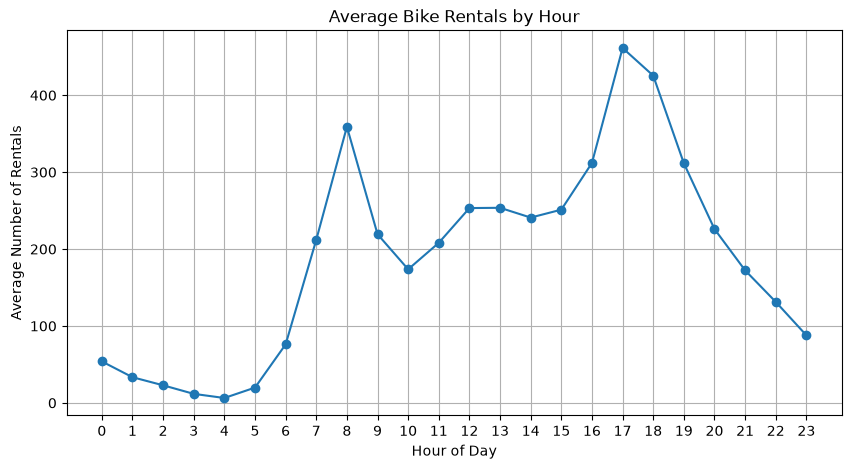

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True)

plt.show()

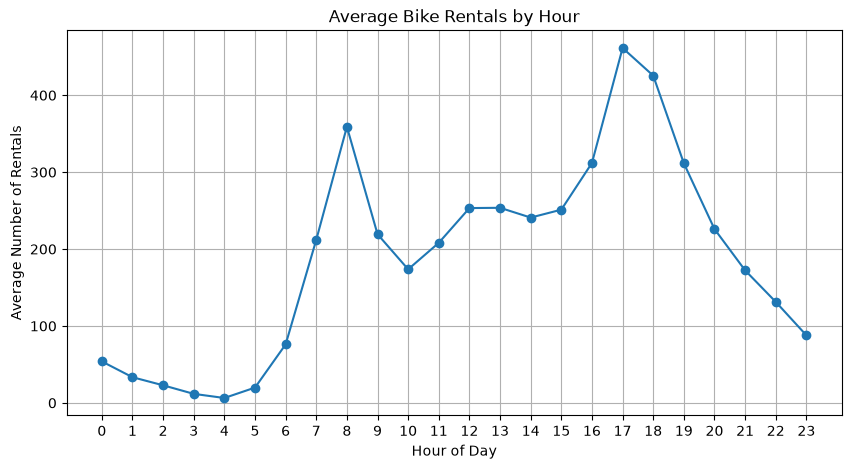

In [7]:
from pathlib import Path

output_dir = Path("reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True)

plt.savefig(output_dir / "hourly_demand.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
import sqlite3
from pathlib import Path

database_dir = Path("data/processed")
database_dir.mkdir(parents=True, exist_ok=True)

connection = sqlite3.connect(database_dir / "bike_sharing.db")

print("Database connected successfully")

Database connected successfully


In [9]:
df.to_sql(
    name="bike_rentals",
    con=connection,
    if_exists="replace",
    index=False
)

print("Data imported successfully")

Data imported successfully


In [10]:
query = """
SELECT
    hr,
    ROUND(AVG(cnt), 2) AS average_rentals
FROM bike_rentals
GROUP BY hr
ORDER BY hr;
"""

sql_hourly_demand = pd.read_sql_query(query, connection)

sql_hourly_demand

,hr,average_rentals
0,0,53.90
1,1,33.38
2,2,22.87
3,3,11.73
4,4,6.35
5,5,19.89
6,6,76.04
7,7,212.06
8,8,359.01
9,9,219.31


In [11]:
query = """
SELECT
    workingday,
    hr,
    ROUND(AVG(cnt), 2) AS average_rentals
FROM bike_rentals
GROUP BY workingday, hr
ORDER BY workingday, hr;
"""

workingday_demand = pd.read_sql_query(query, connection)

workingday_demand.head()

,workingday,hr,average_rentals
0,0,0,90.80
1,0,1,69.51
2,0,2,53.17
3,0,3,25.78
4,0,4,8.26


In [12]:
workdays = workingday_demand[
    workingday_demand["workingday"] == 1
]

non_workdays = workingday_demand[
    workingday_demand["workingday"] == 0
]

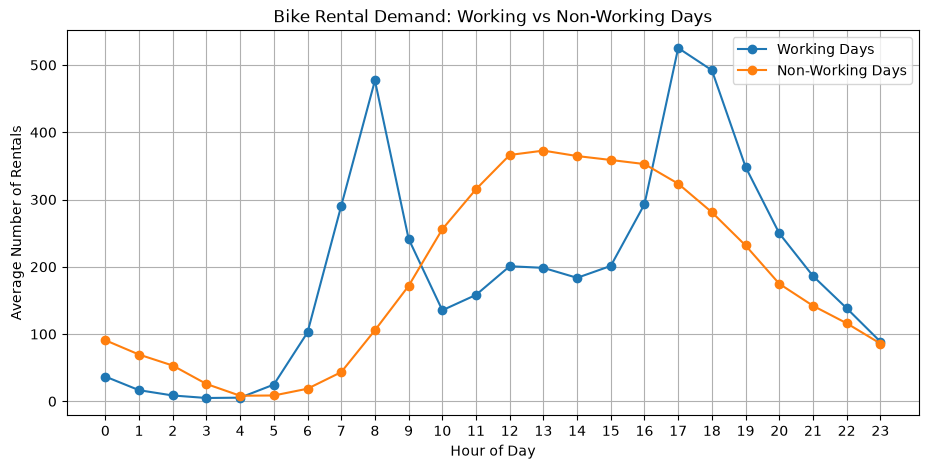

In [13]:
plt.figure(figsize=(11, 5))

plt.plot(
    workdays["hr"],
    workdays["average_rentals"],
    marker="o",
    label="Working Days"
)
plt.plot(
    non_workdays["hr"],
    non_workdays["average_rentals"],
    marker="o",
    label="Non-Working Days"
)

plt.title("Bike Rental Demand: Working vs Non-Working Days")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.legend()
plt.grid(True)

plt.savefig(
    output_dir / "workingday_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [14]:
df["timestamp"] = (
    pd.to_datetime(df["dteday"])
    + pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("timestamp").reset_index(drop=True)

print("Timestamp range:", df["timestamp"].min(), "to", df["timestamp"].max())
df[["timestamp", "cnt"]].head()

Timestamp range: 2011-01-01 00:00:00 to 2012-12-31 23:00:00


,timestamp,cnt
0,2011-01-01 00:00:00,16
1,2011-01-01 01:00:00,40
2,2011-01-01 02:00:00,32
3,2011-01-01 03:00:00,13
4,2011-01-01 04:00:00,1


In [15]:
time_differences = df["timestamp"].diff().dropna()
nonconsecutive_intervals = (
    time_differences != pd.Timedelta(hours=1)
).sum()

print("Non-consecutive intervals:", nonconsecutive_intervals)

Non-consecutive intervals: 75


In [16]:
rentals_by_timestamp = df.set_index("timestamp")["cnt"]

df["lag_1"] = (
    df["timestamp"] - pd.Timedelta(hours=1)
).map(rentals_by_timestamp)

df["lag_24"] = (
    df["timestamp"] - pd.Timedelta(hours=24)
).map(rentals_by_timestamp)

df["lag_168"] = (
    df["timestamp"] - pd.Timedelta(hours=168)
).map(rentals_by_timestamp)

df.loc[
    df["lag_168"].notna(),
    ["timestamp", "cnt", "lag_1", "lag_24", "lag_168"]
].head(10)

,timestamp,cnt,lag_1,lag_24,lag_168
161,2011-01-08 00:00:00,25,15.0,17.0,16.0
162,2011-01-08 01:00:00,16,25.0,7.0,40.0
163,2011-01-08 02:00:00,16,16.0,1.0,32.0
164,2011-01-08 03:00:00,7,16.0,NaN,13.0
165,2011-01-08 04:00:00,1,7.0,1.0,1.0
166,2011-01-08 05:00:00,5,1.0,5.0,1.0
167,2011-01-08 06:00:00,2,5.0,34.0,2.0
168,2011-01-08 07:00:00,9,2.0,84.0,3.0
169,2011-01-08 08:00:00,15,9.0,210.0,8.0
170,2011-01-08 09:00:00,20,15.0,134.0,14.0


In [17]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df[["timestamp", "hour", "day_of_week", "is_weekend", "workingday"]].head()

C:\Users\dmitr\AppData\Local\Temp\ipykernel_54504\4268902624.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["timestamp"].dt.dayofweek


,timestamp,hour,day_of_week,is_weekend,workingday
0,2011-01-01 00:00:00,0,5,1,0
1,2011-01-01 01:00:00,1,5,1,0
2,2011-01-01 02:00:00,2,5,1,0
3,2011-01-01 03:00:00,3,5,1,0
4,2011-01-01 04:00:00,4,5,1,0


In [18]:
feature_columns = [
    "hour",
    "day_of_week",
    "is_weekend",
    "workingday",
    "lag_1",
    "lag_24",
    "lag_168"
]

model_df = df[["timestamp"] + feature_columns + ["cnt"]].copy()

print("Before cleaning:", model_df.shape)

model_df = model_df.dropna(subset=feature_columns)
model_df = model_df.sort_values("timestamp").reset_index(drop=True)

print("After cleaning:", model_df.shape)

X = model_df[feature_columns]
y = model_df["cnt"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
model_df.head()

Before cleaning: (17379, 9)
After cleaning: (16897, 9)
Features shape: (16897, 7)
Target shape: (16897,)


,timestamp,hour,day_of_week,is_weekend,workingday,lag_1,lag_24,lag_168,cnt
0,2011-01-08 00:00:00,0,5,1,0,15.0,17.0,16.0,25
1,2011-01-08 01:00:00,1,5,1,0,25.0,7.0,40.0,16
2,2011-01-08 02:00:00,2,5,1,0,16.0,1.0,32.0,16
3,2011-01-08 04:00:00,4,5,1,0,7.0,1.0,1.0,1
4,2011-01-08 05:00:00,5,5,1,0,1.0,5.0,1.0,5


In [19]:
print("Remaining missing values:")
print(model_df.isnull().sum())

print("Duplicate timestamps:", model_df["timestamp"].duplicated().sum())

Remaining missing values:
timestamp      0
hour           0
day_of_week    0
is_weekend     0
workingday     0
lag_1          0
lag_24         0
lag_168        0
cnt            0
dtype: int64
Duplicate timestamps: 0


In [20]:
split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]
y_train = train_df["cnt"]
y_test = test_df["cnt"]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Train period:", train_df["timestamp"].min(), "to", train_df["timestamp"].max())
print("Test period:", test_df["timestamp"].min(), "to", test_df["timestamp"].max())

Training samples: 13517
Testing samples: 3380
Train period: 2011-01-08 00:00:00 to 2012-08-08 13:00:00
Test period: 2012-08-08 14:00:00 to 2012-12-31 23:00:00


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [22]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [23]:
y_pred = model.predict(X_test)

results = test_df[["timestamp", "cnt"]].copy()
results["predicted"] = y_pred

results.head(10)

,timestamp,cnt,predicted
13517,2012-08-08 14:00:00,236,281.28
13518,2012-08-08 15:00:00,278,277.95
13519,2012-08-08 16:00:00,441,446.30
13520,2012-08-08 17:00:00,858,822.26
13521,2012-08-08 18:00:00,862,831.41
13522,2012-08-08 19:00:00,686,635.71
13523,2012-08-08 20:00:00,500,464.40
13524,2012-08-08 21:00:00,381,337.54
13525,2012-08-08 22:00:00,233,278.51
13526,2012-08-08 23:00:00,136,159.79


In [24]:
mae = mean_absolute_error(y_test, y_pred)

print(f"Random Forest MAE: {mae:.2f} rentals")

Random Forest MAE: 30.50 rentals


In [25]:
baseline_pred = test_df["lag_168"]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

print(f"Baseline MAE: {baseline_mae:.2f} rentals")
print(f"Random Forest MAE: {mae:.2f} rentals")

Baseline MAE: 64.09 rentals
Random Forest MAE: 30.50 rentals


In [26]:
improvement = (
    (baseline_mae - mae) / baseline_mae
) * 100

print(f"MAE improvement: {improvement:.2f}%")

MAE improvement: 52.41%


In [27]:
results["baseline"] = baseline_pred.to_numpy()

results[
    ["timestamp", "cnt", "predicted", "baseline"]
].head(10)

,timestamp,cnt,predicted,baseline
13517,2012-08-08 14:00:00,236,281.28,263.0
13518,2012-08-08 15:00:00,278,277.95,295.0
13519,2012-08-08 16:00:00,441,446.30,479.0
13520,2012-08-08 17:00:00,858,822.26,837.0
13521,2012-08-08 18:00:00,862,831.41,891.0
13522,2012-08-08 19:00:00,686,635.71,652.0
13523,2012-08-08 20:00:00,500,464.40,513.0
13524,2012-08-08 21:00:00,381,337.54,320.0
13525,2012-08-08 22:00:00,233,278.51,288.0
13526,2012-08-08 23:00:00,136,159.79,152.0


In [28]:
plot_df = results[
    results["timestamp"] >= (
        results["timestamp"].max() - pd.Timedelta(days=3)
    )
].copy()

plot_df.head()

,timestamp,cnt,predicted,baseline
16825,2012-12-28 23:00:00,59,40.400,40.0
16826,2012-12-29 00:00:00,26,38.160,31.0
16827,2012-12-29 01:00:00,37,18.770,35.0
16828,2012-12-29 02:00:00,19,22.870,23.0
16829,2012-12-29 03:00:00,6,7.835,7.0


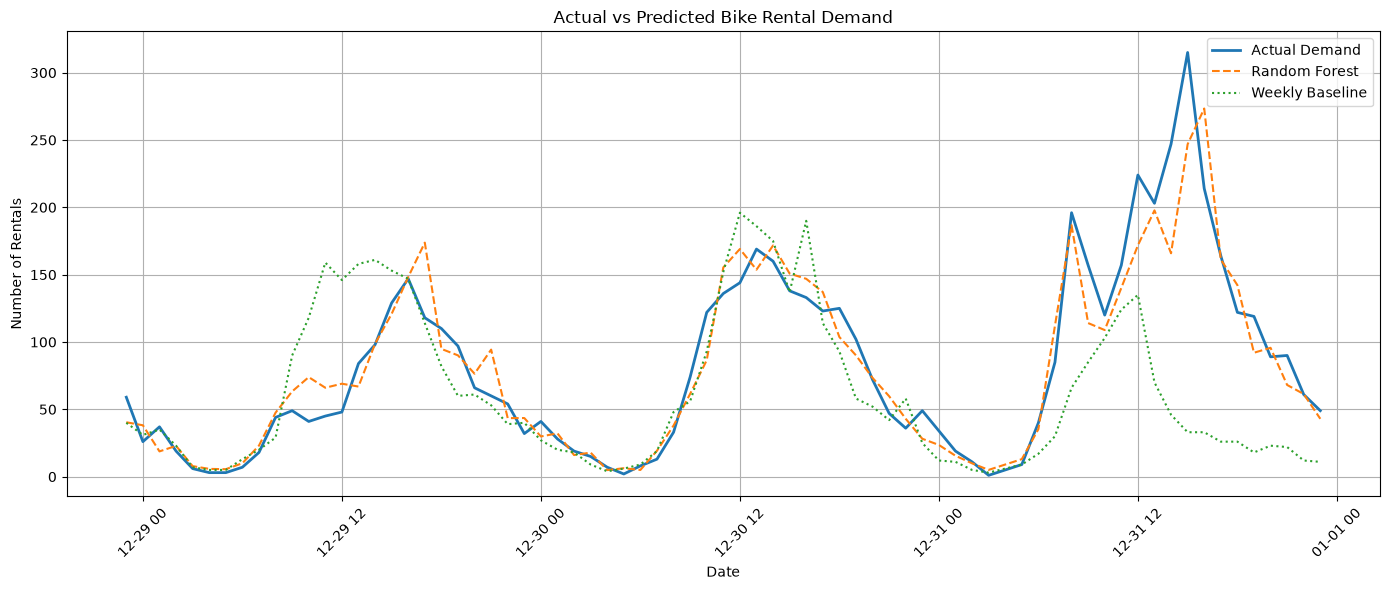

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["timestamp"],
    plot_df["cnt"],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    plot_df["timestamp"],
    plot_df["predicted"],
    label="Random Forest",
    linestyle="--"
)

plt.plot(
    plot_df["timestamp"],
    plot_df["baseline"],
    label="Weekly Baseline",
    linestyle=":"
)

plt.title("Actual vs Predicted Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Number of Rentals")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

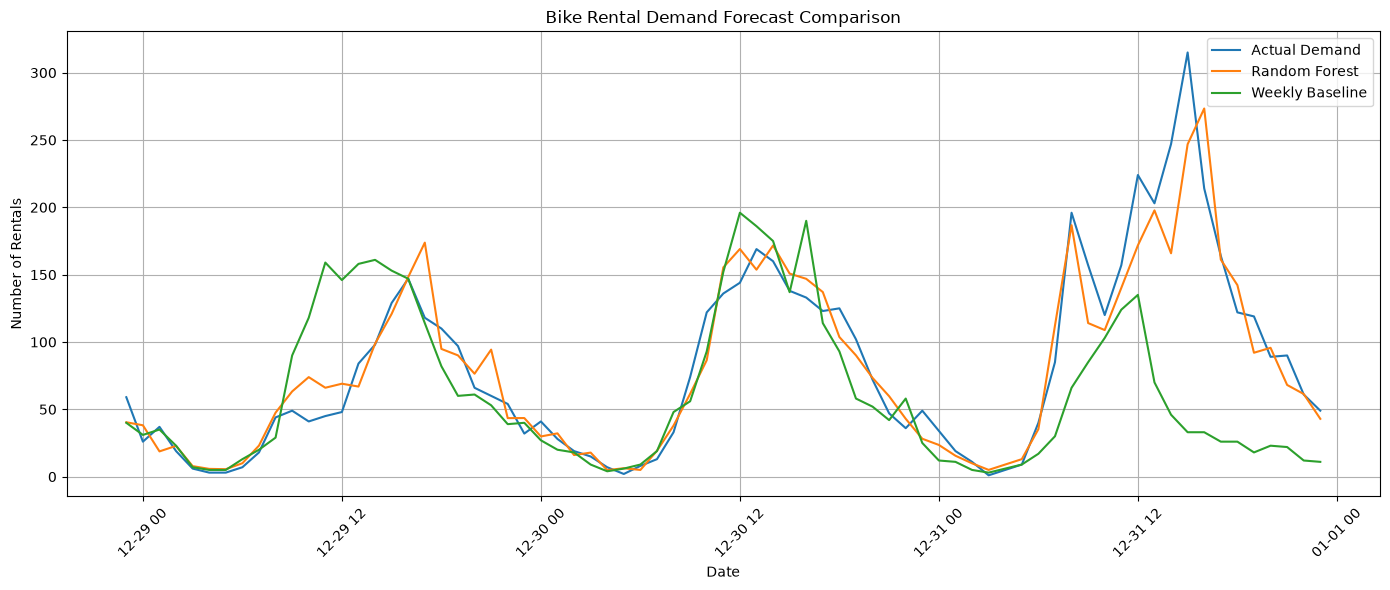

In [30]:
from pathlib import Path

output_dir = Path("reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(14, 6))

plt.plot(plot_df["timestamp"], plot_df["cnt"], label="Actual Demand")
plt.plot(plot_df["timestamp"], plot_df["predicted"], label="Random Forest")
plt.plot(plot_df["timestamp"], plot_df["baseline"], label="Weekly Baseline")

plt.title("Bike Rental Demand Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Number of Rentals")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    output_dir / "forecast_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [31]:
from src.features import build_features

raw_df = pd.read_csv("data/raw/hour.csv")

prepared_df = build_features(raw_df)

prepared_df[
    [
        "timestamp",
        "cnt",
        "lag_1",
        "lag_24",
        "lag_168",
        "is_weekend"
    ]
].loc[prepared_df["lag_168"].notna()].head(10)

,timestamp,cnt,lag_1,lag_24,lag_168,is_weekend
161,2011-01-08 00:00:00,25,15.0,17.0,16.0,1
162,2011-01-08 01:00:00,16,25.0,7.0,40.0,1
163,2011-01-08 02:00:00,16,16.0,1.0,32.0,1
164,2011-01-08 03:00:00,7,16.0,NaN,13.0,1
165,2011-01-08 04:00:00,1,7.0,1.0,1.0,1
166,2011-01-08 05:00:00,5,1.0,5.0,1.0,1
167,2011-01-08 06:00:00,2,5.0,34.0,2.0,1
168,2011-01-08 07:00:00,9,2.0,84.0,3.0,1
169,2011-01-08 08:00:00,15,9.0,210.0,8.0,1
170,2011-01-08 09:00:00,20,15.0,134.0,14.0,1
